# 03. Hybrid Filtering (Combining CF and CBF Rankings)
**Machine Learning Team Project, Team 2 | Music Artist Recommendation (Last.fm)**  |  Model Evaluation and Result Integration

---
## Purpose
This notebook implements **hybrid filtering**, which combines the recommendation rankings of **collaborative filtering (CF)** and **content-based filtering (CBF)**. The two models use different information.
- **CF**: Finds similar users from listening records (who listened to what) and recommends from them. It is accurate but tends to concentrate recommendations on already popular artists.
- **CBF**: Recommends by the similarity of the tags (genre, mood) attached to artists. It also recommends less well-known artists, so diversity is higher, but accuracy is lower.

The strengths and weaknesses of the two methods are opposite, so the goal is to check whether combining the rankings can keep CF's accuracy while gaining some of CBF's diversity. The performance comparison between models and the statistical analysis are done in the **04 integrated evaluation notebook**, and the output of this notebook is the input of 04.

## Overall Processing Flow
```
[0] Define settings and constants
 -> [1] Load the preprocessed data and check split leakage
 -> [2] Define the CF and CBF model functions (existing notebook code, used without modification)
 -> [3] Define the hybrid combination function fuse()
 -> [4] Dataset A: define common candidates -> search and fix the weight w on validation -> generate test recommendations
 -> [5] Dataset B: (5-1) official CF and popularity recommendations under the CF notebook's conditions -> (5-2) recommendations of the 4 models on the common candidates with the fixed w
 -> [6] Save settings and outputs (input of notebook 04)
```

## Design Policy (why it is implemented this way)
1. **CF and CBF code is reused without modification.** The input of the hybrid (each model's Top-50) must equal the recommendations of the original notebooks so that the effect of the hybrid can be measured cleanly.
2. **The four models recommend from the same candidate set.** CF can recommend every observed artist, but CBF can recommend only artists with tags, so the candidates differ. With different candidates, accuracy and diversity (coverage) cannot be compared fairly, so they are aligned to the intersection of the two sets (the common candidates).
3. **Rankings, not scores, are combined.** CF scores (weighted sum of neighbor similarity) and CBF scores (cosine similarity) have different ranges and meanings and cannot be added directly.
4. **The reference figures for Dataset B follow the evaluation conditions of the CF notebook.** On B, CF and popularity are first recommended and evaluated under exactly the same conditions as the CF notebook (the whole B history, all candidates, all ground truth) to reproduce the official figures. The common-candidate results are a supplementary standard for relative comparison including CBF and the hybrid.
5. **The weight is chosen only on the validation split of Dataset A.** Test and Dataset B are used only for the final evaluation, which keeps evaluation data out of the selection process (data leakage).

## Evaluation Principles
- Settings are selected only by A-validation NDCG@10; A-test and B are used only for the final evaluation; settings are never changed using B.
- The hybrid weight is also chosen only on A-validation and applied to B unchanged.
- Test records are not used to compute similarities, profiles, or popularity.

## Hybrid Method: Weighted RRF
CF scores (sum of neighbor similarities) and CBF scores (cosine similarity) have **different scales, so the scores cannot be added directly.** We therefore use RRF, which combines **ranks** instead of scores.

$$\text{score}(u,i)=w\cdot\frac{1}{c+\text{rank}_{CF}(u,i)}+(1-w)\cdot\frac{1}{c+\text{rank}_{CBF}(u,i)}$$

- An artist that appears in only one list receives only that model's term. An artist in both lists receives both terms and moves up.
- `c = 60` is the constant recommended by Cormack et al. (2009) and is fixed. The only tuned value is the CF weight `w` (0 to 1 in steps of 0.1).
- The candidates combined from the two models are each model's **Top-50**.
- **Common candidates:** CF, CBF, popularity, and the hybrid all recommend from the same candidate set (CBF candidates ∩ observed artists), which removes distortion from differences in the coverage denominator and the candidate set.

Source: Cormack, G. V., Clarke, C. L. A., & Büttcher, S. (2009). Reciprocal rank fusion outperforms Condorcet and individual rank learning methods. *SIGIR '09*.

## 0. Settings and Constants
The values used by the hybrid are defined in one place.
- `TOPK = 10`: length of the final recommendation and of the evaluation.
- `POOL = 50`: length of each model's candidate list used for the combination. The final recommendation has 10 items, but the pool is generous so that an artist ranked outside the top 10 (for example 11th to 50th) by one model can rise to the top when combined with its rank in the other model.
- `RRF_C = 60`: the RRF constant. The value recommended in the original paper (Cormack et al., 2009) is used as is and is not tuned. Limiting the tuned quantity to the single weight `w` reduces the search range and the risk of overfitting.
- `W_GRID`: search range of the CF weight `w` (0.0 to 1.0 in steps of 0.1). The two ends equal CBF alone (0.0) and CF alone (1.0) and serve as references for the effect of the combination.
- This notebook uses the settings fixed in the CF and CBF notebooks as they are (`k=30`, log1p weighting / raw TF, uniform profile). If a settings file exists it is read; otherwise the same defaults are used.

In [25]:
# 0. Settings
import os, io, json, zipfile, pathlib, hashlib, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from sklearn.feature_extraction.text import TfidfTransformer
from sklearn.preprocessing import normalize
from IPython.display import display
warnings.filterwarnings('ignore')

SEED = 42
np.random.seed(SEED)
TOPK = 10                 # Length of the final recommendation and of the evaluation
POOL = 50                 # Length of each model’s candidate list that the hybrid combines
RRF_C = 60                # RRF constant (value recommended by Cormack et al., 2009)
W_GRID = [round(x, 1) for x in np.arange(0, 1.01, 0.1)]     # Search range of the CF weight (0 = CBF only, 1 = CF only)

# ---- Path settings --------------------------------------------------------------------------
BASE_DIR = pathlib.Path.cwd()          # Working folder (the folder with this notebook). To use another location, set it directly: pathlib.Path('/path/to/ml_project')
ZIP_PATH = None                        # Set this to give the preprocessed ZIP path directly (if None, the ZIP is searched in BASE_DIR and BASE_DIR/data)
OUT = BASE_DIR / 'hybrid_outputs'; OUT.mkdir(parents=True, exist_ok=True)
# Confirmed-settings files of the CF and CBF notebooks (read if present, otherwise defaults are used)
CF_CONFIG_PATH = BASE_DIR / 'cf_outputs' / 'selected_config.json'
CBF_CONFIG_PATH = BASE_DIR / 'cbf_outputs' / 'selected_config.json'
CF_DEFAULT = {'k': 30, 'weight': 'log'}                       # Final result of the CF notebook (by A-validation NDCG@10)
CBF_DEFAULT = {'tf_mode': 'raw', 'weight_mode': 'uniform'}    # Final result of the CBF notebook

def load_config(path, default, name):
    if path.exists():
        cfg = json.loads(path.read_text(encoding='utf-8')); print(f'{name} 설정을 {path} 에서 읽음:', {k: cfg[k] for k in default}); return {k: cfg[k] for k in default}
    print(f'{name} 설정 파일이 없어 기본값 사용:', default); return dict(default)
CF_CFG = load_config(CF_CONFIG_PATH, CF_DEFAULT, 'CF')
CBF_CFG = load_config(CBF_CONFIG_PATH, CBF_DEFAULT, 'CBF')
print('결과 저장 위치:', OUT)

CF 설정을 ./cf_outputs/selected_config.json 에서 읽음: {'k': 30, 'weight': 'log'}
CBF 설정을 ./cbf_outputs/selected_config.json 에서 읽음: {'tf_mode': 'raw', 'weight_mode': 'uniform'}
결과 저장 위치: ./hybrid_outputs


## 1. Load the Preprocessed ZIP
It uses the same ZIP and the same file paths as the CF and CBF notebooks. The BOM at the start of each CSV is handled with `utf-8-sig`, and the ZIP is read directly without being extracted.

In [26]:
# 1-1. Open the ZIP and read files
def find_zip():
    """Return the preprocessed ZIP path. If ZIP_PATH is not set, search BASE_DIR and BASE_DIR/data (excluding result ZIPs)."""
    if ZIP_PATH is not None:
        p = pathlib.Path(ZIP_PATH); assert p.exists(), f'{p} 파일이 없습니다.'; return p
    hits = [p for d in (BASE_DIR, BASE_DIR / 'data') if d.exists() for p in d.glob('*.zip') if not p.stem.endswith('_outputs')]
    assert len(hits) == 1, f'전처리 ZIP을 정확히 1개 찾아야 합니다. 찾은 파일: {[str(h) for h in hits]} → ZIP_PATH를 직접 지정하세요.'
    return hits[0]

ZIP_FILE = find_zip()
print('전처리 ZIP:', ZIP_FILE, '| SHA256:', hashlib.sha256(ZIP_FILE.read_bytes()).hexdigest()[:16], '...')
def open_zip():
    return zipfile.ZipFile(ZIP_FILE)

Z = open_zip(); NAMES = set(Z.namelist())
SPLITS = ('train', 'validation', 'test')
REQ_A = ['Lastfm.2k-a/artists.csv', 'Lastfm.2k-a/artist_tag_counts.csv', *[f'Lastfm.2k-a/{s}.csv' for s in SPLITS]]
REQ_B = ['Lastfm.360k-b/content_candidate_artists.csv'] + \
        [f'Lastfm.360k-b/content_external_candidates/{s}.csv' for s in SPLITS]
REQ_B_FULL = [f'Lastfm.360k-b/{s}.csv' for s in SPLITS]           # Full B files used by the CF notebook
assert set(REQ_A) <= NAMES, f'A 필수 파일 누락: {set(REQ_A) - NAMES}'
RUN_B = set(REQ_B) <= NAMES
RUN_B_FULL = set(REQ_B_FULL) <= NAMES
print('A 파일 확인 완료 | B 파일', '모두 있음 → B까지 실행' if RUN_B else f'누락 {sorted(set(REQ_B) - NAMES)} → B는 건너뜀')
rd = lambda f: pd.read_csv(Z.open(f), encoding='utf-8-sig', low_memory=False)

a_art, tags = rd('Lastfm.2k-a/artists.csv'), rd('Lastfm.2k-a/artist_tag_counts.csv')
a = {s: rd(f'Lastfm.2k-a/{s}.csv') for s in SPLITS}
if RUN_B:
    b_ext = {s: rd(f'Lastfm.360k-b/content_external_candidates/{s}.csv') for s in SPLITS}        # B common candidates only, as used by CBF
    b_map = rd('Lastfm.360k-b/content_candidate_artists.csv')
if RUN_B_FULL:
    b_full = {s: rd(f'Lastfm.360k-b/{s}.csv') for s in SPLITS}                                    # Full B data as used by the CF notebook
    for s, d in b_full.items(): print('B 전체', s, d.shape)
for label, parts in [('A', a)] + ([('B 공통후보', b_ext)] if RUN_B else []):
    for s, d in parts.items(): print(label, s, d.shape)

전처리 ZIP: ./data/전처리데이터.zip | SHA256: 9ef1b2df065009cc ...
A 파일 확인 완료 | B 파일 모두 있음 → B까지 실행
B 전체 train (301797, 6)
B 전체 validation (93948, 6)
B 전체 test (93948, 6)
A train (55721, 6)
A validation (18540, 6)
A test (18540, 6)
B 공통후보 train (214507, 6)
B 공통후보 validation (64966, 6)
B 공통후보 test (64966, 6)


### Split Leakage Check
If the same (user, artist) pair appears in train, validation, and test, the model would be hitting an answer it has already seen and performance would be inflated. Before the evaluation, we check that the three splits do not overlap and that all artists in the training data are in the artist list.

In [27]:
# 1-2. Split leakage check (A)
pairs = lambda d: set(zip(d.user_id, d.artist_id))
assert not (pairs(a['train']) & pairs(a['validation'])) and not (pairs(a['train']) & pairs(a['test'])) and not (pairs(a['validation']) & pairs(a['test']))
assert set(a['train'].artist_id) <= set(a_art.artist_id)
print('A: 분할 간 (사용자, 아티스트) 중복 없음 확인')

A: 분할 간 (사용자, 아티스트) 중복 없음 확인


## 2. CF and CBF Model Functions (used without modification)
The code below is copied **as is** from the functions of the CF and CBF notebooks, so that the input of the hybrid (Top-50) equals each model's recommendations. The principle of each model is summarized before its code.

### 2-1. User-based CF and the Popularity Baseline
**User × artist matrix.** Play counts are converted with `log(1 + plays)` so that a few heavy listening records do not dominate, and used as the values of the matrix $R$ (`build_matrix`).

**User similarity.** The cosine similarity between the listening vectors of two users $u, v$ is used. If the rows are L2-normalized, one matrix product gives the similarity of all user pairs.
$$\text{sim}(u,v)=\frac{R_u\cdot R_v}{\lVert R_u\rVert\,\lVert R_v\rVert}$$

**Recommendation score.** Only the $k$ neighbors $N_k(u)$ with the highest similarity are kept (`neighbor_similarity`), and artists that neighbors listened to more get higher scores.
$$\text{score}(u,i)=\sum_{v\in N_k(u)}\text{sim}(u,v)\cdot R_{v,i}$$
Artists already heard are excluded (handled with `-inf`), and the top $K$ by score are recommended (`recommend_ucf`). With many users, computing the whole similarity matrix at once runs out of memory, so the computation is split into `batch` units. Artists that no neighbor listened to (score 0) have no evidence and are not recommended.

**Popularity baseline** (`recommend_pop`). Without personalization, it recommends in descending order of the number of distinct listeners. It is the comparison point for checking whether the personalized models are actually better than this simple standard.

In [28]:
# 2-1. CF and popularity (Section 4 of the CF notebook)
def build_matrix(history, artist_ids, value='log'):
    """[CF notebook] User x artist sparse matrix R. value='log' uses log1p(plays), 'binary' uses 1"""
    users = sorted(history.user_id.unique().tolist())
    uidx = {u: i for i, u in enumerate(users)}
    aidx = {x: i for i, x in enumerate(artist_ids)}
    h = history[history.artist_id.isin(aidx)]
    if value == 'log':
        vals = h.log1p_plays.to_numpy(dtype=float)
    elif value == 'binary':
        vals = np.ones(len(h))
    else:
        raise ValueError(value)
    R = sparse.csr_matrix((vals, (h.user_id.map(uidx).to_numpy(), h.artist_id.map(aidx).to_numpy())),
                          shape=(len(users), len(artist_ids)))
    return users, R

def neighbor_similarity(Rn, start, end, k):
    """[CF notebook] Build the cosine-similarity rows for users start..end (batch x all users) and keep only the top k"""
    S = (Rn[start:end] @ Rn.T).toarray()
    np.fill_diagonal(S[:, start:end], 0.0)              # Exclude the user itself from the neighbors
    if k < S.shape[1]:
        drop = np.argpartition(-S, k, axis=1)[:, k:]    # Positions outside the top k
        np.put_along_axis(S, drop, 0.0, axis=1)         # -> set to 0 to drop them from the neighbors
    return S

def recommend_ucf(history, k=50, value='log', topk=TOPK, allowed=None, batch=512):
    """[CF notebook] User-based CF Top-k recommendation.
    history: observed listening history / k: number of neighbors / value: 'log'|'binary' / allowed: set of artists allowed for recommendation (None = all)
    Returns: (recommendation DataFrame[user_id, artist_id, score, rank], list of candidates)"""
    cand = sorted(history.artist_id.unique().tolist())
    users, R = build_matrix(history, cand, value)
    Rn = normalize(R, norm='l2', axis=1)
    seen = (R > 0).tocsr()
    block = None if allowed is None else ~np.isin(np.array(cand, dtype=object), list(allowed))
    out_u, out_a, out_s, out_r = [], [], [], []
    cand_arr = np.array(cand, dtype=object)
    for s in range(0, len(users), batch):
        e = min(s + batch, len(users))
        S = neighbor_similarity(Rn, s, e, k)
        scores = (sparse.csr_matrix(S) @ R).toarray()   # Σ sim(u,v)·r(v,i)
        scores[seen[s:e].toarray()] = -np.inf             # Exclude artists already heard
        if block is not None:
            scores[:, block] = -np.inf                    # Restrict candidates (supplementary experiment)
        top = np.argpartition(-scores, topk, axis=1)[:, :topk]
        for j in range(e - s):
            idx = top[j][np.argsort(-scores[j, top[j]], kind='stable')]
            idx = idx[scores[j, idx] > 0]                 # Drop artists that no neighbor listened to
            out_u += [users[s + j]] * len(idx); out_a += cand_arr[idx].tolist()
            out_s += scores[j, idx].tolist(); out_r += list(range(1, len(idx) + 1))
    recs = pd.DataFrame({'user_id': out_u, 'artist_id': out_a, 'score': out_s, 'rank': out_r})
    if allowed is not None:
        cand = [x for x in cand if x in allowed]
    return recs, cand

def recommend_pop(history, topk=TOPK, allowed=None):
    """[CF notebook] Popularity baseline: descending number of distinct listeners per artist (ties by artist_id), excluding artists already heard"""
    pop = history.groupby('artist_id').user_id.nunique().rename('n').reset_index()
    if allowed is not None:
        pop = pop[pop.artist_id.isin(allowed)]
    pop['key'] = pop.artist_id.astype(str)
    pop = pop.sort_values(['n', 'key'], ascending=[False, True])
    order, counts = pop.artist_id.tolist(), pop.n.tolist()
    seen = history.groupby('user_id').artist_id.agg(set).to_dict()
    rec = []
    for u in sorted(seen):
        r = 0
        for x, c in zip(order, counts):
            if x in seen[u]: continue
            r += 1; rec.append((u, x, float(c), r))
            if r == topk: break
    return pd.DataFrame(rec, columns=['user_id', 'artist_id', 'score', 'rank']), order

### 2-2. Content-Based Filtering (CBF)
**Artist vectors.** The tags attached to an artist are treated as words to build a TF-IDF vector. L2 normalization keeps artists with many tags from being favored (`make_artist_vectors`).
$$\text{tfidf}(a,t)=\text{tf}(a,t)\times\text{idf}(t),\qquad \text{idf}(t)=\ln\frac{1+n}{1+\text{df}(t)}+1$$
Here $\text{tf}(a,t)$ is the number of users who attached tag $t$ to artist $a$ (raw), $\text{df}(t)$ is the number of artists having tag $t$, and $n$ is the number of artists. Common tags attached to almost every artist get lower weights, and tags attached only to specific artists have more discriminative power.

**User profile.** The vectors of the artists the user listened to are summed (with uniform weights) and normalized (`build_profiles`). The profile becomes a vector that points in the direction of the user's taste.

**Recommendation.** The Top-$K$ are recommended in descending order of the cosine similarity between the profile and the candidate artist vectors (`recommend`). Ties are broken by artist_id so that every run gives the same result. Artists with fewer than 2 tags have unstable vectors and are excluded from the recommendation candidates (`content_eligible`).

In [29]:
# 2-2. CBF (Sections 3-4 of the CBF notebook)
eligible = a_art.loc[a_art.content_eligible.eq(1), 'artist_id'].tolist()
assert len(eligible) > 0
artist_to_row = {v: i for i, v in enumerate(eligible)}
used_tags = tags[tags.artist_id.isin(artist_to_row)].copy()
terms = sorted(used_tags.tag.unique().tolist())
term_to_col = {t: i for i, t in enumerate(terms)}
rows = used_tags.artist_id.map(artist_to_row).to_numpy()
cols = used_tags.tag.map(term_to_col).to_numpy()
vals = used_tags.distinct_user_count.to_numpy(dtype=np.float64)
TF = sparse.csr_matrix((vals, (rows, cols)), shape=(len(eligible), len(terms)))
assert (np.diff(TF.indptr) >= 2).all(), 'eligible artist에 태그 2개 미만 존재'
print('TF matrix:', TF.shape, 'nonzero:', TF.nnz)

def make_artist_vectors(tf_mode='raw', sublinear_tf=False):
    """[CBF notebook] Tag TF (raw|binary) x smoothed IDF, rows L2-normalized"""
    if tf_mode == 'raw': X = TF.copy()
    elif tf_mode == 'binary':
        X = TF.copy(); X.data = np.ones_like(X.data)
    else: raise ValueError(tf_mode)
    trans = TfidfTransformer(norm='l2', use_idf=True, smooth_idf=True, sublinear_tf=sublinear_tf)
    return trans.fit_transform(X).tocsr()

def build_profiles(history, V, weight_mode):
    """[CBF notebook] User profile: weighted sum (uniform|log) of the TF-IDF vectors of the listened artists, then L2 normalization"""
    users = sorted(history.user_id.unique().tolist())
    uidx = {u: i for i, u in enumerate(users)}
    h = history[history.artist_id.isin(artist_to_row)].copy()
    if weight_mode == 'uniform': w = np.ones(len(h))
    elif weight_mode == 'log': w = h.log1p_plays.to_numpy(dtype=float)
    else: raise ValueError(weight_mode)
    mat = sparse.csr_matrix((w, (h.user_id.map(uidx).to_numpy(), h.artist_id.map(artist_to_row).to_numpy())), shape=(len(users), len(eligible)))
    prof = normalize(mat @ V, norm='l2', axis=1).tocsr()
    valid = np.asarray(prof.getnnz(axis=1) > 0)
    return users, prof, valid

def recommend(history, V, weight_mode, candidate_ids, topk=10, batch_size=128):
    """[CBF notebook] Top-k cosine similarity between profile and candidate artist vectors (excluding artists already heard)"""
    users, profiles, valid = build_profiles(history, V, weight_mode)
    candidate_ids = [i for i in candidate_ids if i in artist_to_row]
    assert len(candidate_ids) > 0
    candidate_rows = np.array([artist_to_row[i] for i in candidate_ids])
    CV = V[candidate_rows]
    cand_pos = {artist: i for i, artist in enumerate(candidate_ids)}
    listened = history.groupby('user_id').artist_id.agg(set).to_dict()
    records = []
    for start in range(0, len(users), batch_size):
        end = min(start + batch_size, len(users))
        scores = (profiles[start:end] @ CV.T).toarray()
        for j, user in enumerate(users[start:end]):
            if not valid[start + j]: continue
            seen = [cand_pos[x] for x in listened[user] if x in cand_pos]
            scores[j, seen] = -np.inf
            finite = np.isfinite(scores[j]); count = min(topk, int(finite.sum()))
            if count == 0: continue
            # stable ties: ascending candidate_ids first
            inds = np.argpartition(-scores[j], count - 1)[:count]
            inds = sorted(inds, key=lambda k: (-scores[j, k], candidate_ids[k]))
            for rank, k in enumerate(inds, 1):
                records.append((user, candidate_ids[k], float(scores[j, k]), rank))
    result = pd.DataFrame(records, columns=['user_id', 'artist_id', 'score', 'rank'])
    assert not result.duplicated(['user_id', 'artist_id']).any()
    assert (result['rank'] <= topk).all()
    assert not any(x in listened[u] for u, x in zip(result.user_id, result.artist_id))
    return result, pd.DataFrame({'user_id': users, 'profile_available': valid})

V = make_artist_vectors(CBF_CFG['tf_mode'])
A_CAND = sorted(eligible)          # Same as the A candidate definition of the CBF notebook

TF matrix: (10425, 9583) nonzero: 106725


### 2-3. Evaluation Metrics
For each user, the hidden ground-truth set $G_u$ is compared with the recommendation list $L_u$ (length $K=10$).
$$\text{Precision@}K=\frac{|L_u\cap G_u|}{K},\qquad \text{Recall@}K=\frac{|L_u\cap G_u|}{|G_u|}$$
$$\text{DCG@}K=\sum_{r=1}^{K}\frac{\text{rel}_r}{\log_2(r+1)},\qquad \text{NDCG@}K=\frac{\text{DCG@}K}{\text{IDCG@}K}$$
NDCG gives higher scores when hits are placed higher, so it reflects the quality of the ranking, and IDCG is the DCG when all hits are placed at the top (based on $\min(K,|G_u|)$ items). **Catalog Coverage** is the number of distinct artists that appear at least once in the recommendations divided by the number of candidates, and it shows the diversity of the recommendations. The `conditional_*` metrics, based only on ground truth inside the candidates, are supplementary metrics for separating the limitation caused by ground truth outside the candidates.
The same functions as in the two notebooks are used and unit-tested on small examples, which guarantees that the computation is identical for all models.

In [30]:
# 2-3. Evaluation function (shared by both notebooks, unmodified)
def evaluate(recs, truth, users, candidate_ids, k=10):
    users = list(users); truth_by = truth.groupby('user_id').artist_id.agg(set).to_dict()
    pred_by = recs.sort_values('rank').groupby('user_id').artist_id.agg(list).to_dict() if len(recs) else {}
    cand = set(candidate_ids); discount = 1 / np.log2(np.arange(2, k + 2))
    records = []
    for u in users:
        gt = truth_by.get(u, set()); pred = pred_by.get(u, [])
        assert len(gt) > 0, f'{u}: 정답 없는 사용자'
        hit = np.array([int(x in gt) for x in pred[:k]], dtype=float)
        dcg = float((hit * discount[:len(hit)]).sum())
        reachable = gt & cand
        records.append({'user_id': u, 'precision10': float(hit.sum() / k),
           'recall10': float(hit.sum() / len(gt)),
           'ndcg10': float(dcg / discount[:min(k, len(gt))].sum()),
           'conditional_recall10': float(hit.sum() / len(reachable)) if reachable else np.nan,
           'conditional_ndcg10': float(dcg / discount[:min(k, len(reachable))].sum()) if reachable else np.nan,
           'gt_count': len(gt), 'reachable_gt': len(reachable), 'hits': int(hit.sum()), 'recommendations': len(pred)})
    per = pd.DataFrame(records)
    summary = {c: float(per[c].mean()) for c in ['precision10', 'recall10', 'ndcg10', 'conditional_recall10', 'conditional_ndcg10']}
    summary.update({'catalog_coverage': float(recs.artist_id.nunique() / len(cand)),
       'reachable_gt_fraction': float(per.reachable_gt.sum() / per.gt_count.sum()),
       'users': len(users), 'users_with_reachable_gt': int((per.reachable_gt > 0).sum()),
       'recommended_users': int((per.recommendations > 0).sum()), 'catalog_size': len(cand)})
    return summary, per

_s, _ = evaluate(pd.DataFrame({'user_id': ['u'], 'artist_id': [101], 'rank': [1], 'score': [1.]}),
                 pd.DataFrame({'user_id': ['u'], 'artist_id': [101]}), ['u'], [101, 102], 10)
assert np.isclose(_s['precision10'], .1) and np.isclose(_s['recall10'], 1.) and np.isclose(_s['ndcg10'], 1.)
print('evaluate() 단위 테스트 통과')

evaluate() 단위 테스트 통과


## 3. Hybrid Combination Function
`fuse()` merges the Top-50 lists of CF and CBF with the weighted RRF score and then picks the top $K$ per user.
- If the same (user, artist) is in both lists, the two terms are added and the score becomes larger. In other words, **artists recommended by both models take priority**, and an artist in only one list is reflected only by that model's weight.
- Ties are sorted by artist_id so that the result is always the same.
- `check_recs()` is the result check function. It checks that recommendations come only from the candidates, that there are no already-heard artists, that there are no duplicates, and that the per-user count limit is kept.
- The small example at the end is a unit test that directly checks the core behavior of `fuse()`: "an artist in both lists ranks first."

In [31]:
# 3-1. fuse() and check functions
def fuse(r_cf, r_cbf, w, k=TOPK, c=RRF_C):
    """Combine the CF and CBF lists (user_id, artist_id, rank) with weighted RRF and return the top k per user.
    score = w/(c+rank_CF) + (1-w)/(c+rank_CBF); if in only one list, add only that term; ties by artist_id."""
    a_ = r_cf.assign(s=w / (c + r_cf['rank'])); b_ = r_cbf.assign(s=(1 - w) / (c + r_cbf['rank']))
    f = pd.concat([a_[['user_id', 'artist_id', 's']], b_[['user_id', 'artist_id', 's']]]).groupby(['user_id', 'artist_id'], as_index=False).s.sum()
    f = f.sort_values(['user_id', 's', 'artist_id'], ascending=[True, False, True])
    f['rank'] = f.groupby('user_id').cumcount() + 1
    return f[f['rank'] <= k].rename(columns={'s': 'score'})[['user_id', 'artist_id', 'score', 'rank']].reset_index(drop=True)

def top(recs, k=TOPK):
    """Keep only the top k of the Top-50 list"""
    return recs[recs['rank'] <= k].reset_index(drop=True)

def check_recs(name, history, recs, allowed_ids):
    """Recommendation check: only inside the candidates, no already-heard artists, no duplicate (user, rank) or (user, artist), at most TOPK per user"""
    seen = history.groupby('user_id').artist_id.agg(set).to_dict()
    assert set(recs.artist_id) <= set(allowed_ids), f'{name}: 후보 밖 추천'
    assert not any(x in seen.get(u, ()) for u, x in zip(recs.user_id, recs.artist_id)), f'{name}: 이미 들은 아티스트 추천'
    assert not recs.duplicated(['user_id', 'rank']).any() and not recs.duplicated(['user_id', 'artist_id']).any(), f'{name}: 중복'
    assert recs.groupby('user_id').size().max() <= TOPK, f'{name}: 사용자당 {TOPK}개 초과'
    print(f'  {name}: 검증 통과 (추천 {len(recs):,}행, 사용자 {recs.user_id.nunique():,}명)')

# Small behavior check: an artist in both the CF and CBF lists must rank above one in only a single list
_cf = pd.DataFrame({'user_id': [1, 1], 'artist_id': [10, 20], 'rank': [1, 2]})
_cbf = pd.DataFrame({'user_id': [1, 1], 'artist_id': [30, 20], 'rank': [1, 2]})
_f = fuse(_cf, _cbf, 0.5, k=3)
assert _f.artist_id.tolist()[0] == 20, _f
print('fuse() 단위 테스트 통과 (양쪽 목록에 모두 있는 아티스트가 1위)')

fuse() 단위 테스트 통과 (양쪽 목록에 모두 있는 아티스트가 1위)


## 4. Dataset A: Weight Selection (Validation) -> Test Recommendations
**Common candidates** = `CBF candidates (content_eligible=1) ∩ artists appearing in the observed history`. Popularity, CF, CBF, and the hybrid all recommend only from this set.
Weight selection: observed history = **train**, ground truth = **validation**. A-test is not used at this stage.
The selection criterion is **maximum NDCG@10**, which reflects the quality of the ranking; ties are broken by Recall@10 -> Precision@10 -> the smaller $w$. This rule makes the result unique even when values are equal, and it is the same rule the CF and CBF notebooks used to choose their settings. Coverage is not part of the selection criterion and is recorded only to show the trade-off with accuracy.

A 공통 후보 9,444개 (CBF 후보 10,425개 중 관측된 아티스트) | 평가 사용자 1,877명
가중치 탐색 2.4초


,w_cf,precision10,recall10,ndcg10,catalog_coverage
0,0.9,0.1439,0.1461,0.1671,0.0826
1,0.8,0.1440,0.1462,0.1662,0.0967
2,0.7,0.1404,0.1428,0.1642,0.1141
3,0.6,0.1389,0.1414,0.1624,0.1225
4,1.0,0.1412,0.1432,0.1623,0.0770
5,0.5,0.1374,0.1396,0.1601,0.1670
6,0.4,0.1320,0.1342,0.1554,0.2062
7,0.3,0.1290,0.1308,0.1518,0.2156
8,0.2,0.1207,0.1225,0.1427,0.2334
9,0.1,0.1070,0.1084,0.1279,0.2425


A-validation NDCG@10 기준으로 확정한 CF 가중치 w = 0.9  (CBF 가중치 = 0.1)


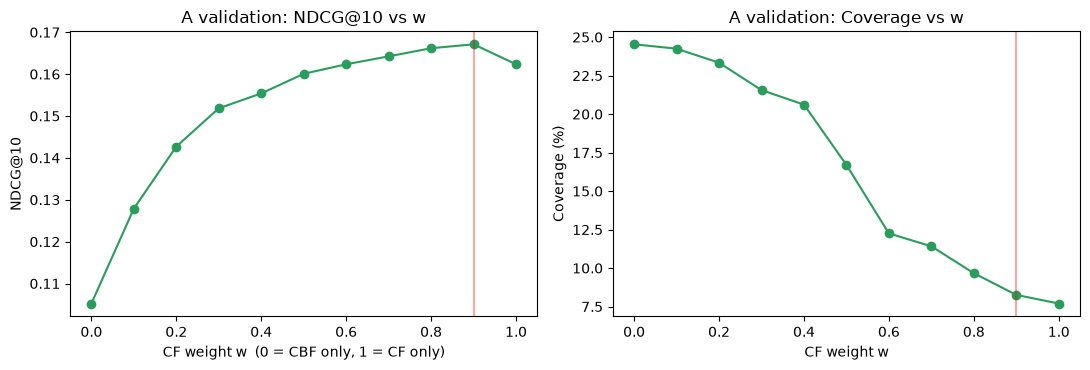

In [32]:
# 4-1. A common candidates and weight search (A-validation)
A_HIST = pd.concat([a['train'], a['validation']], ignore_index=True)      # Observed history for the test evaluation
A_USERS = sorted(A_HIST.user_id.unique())
COMMON_A = sorted(set(A_CAND) & set(A_HIST.artist_id))
print(f'A 공통 후보 {len(COMMON_A):,}개 (CBF 후보 {len(A_CAND):,}개 중 관측된 아티스트) | 평가 사용자 {len(A_USERS):,}명')

t0 = time.time()
A_TRAIN_USERS = sorted(a['train'].user_id.unique())
v_cf, _ = recommend_ucf(a['train'], k=CF_CFG['k'], value=CF_CFG['weight'], topk=POOL, allowed=set(COMMON_A))
v_cbf, _ = recommend(a['train'], V, CBF_CFG['weight_mode'], COMMON_A, topk=POOL)
val_rows = []
for w in W_GRID:
    s, _ = evaluate(fuse(v_cf, v_cbf, w), a['validation'], A_TRAIN_USERS, COMMON_A)
    val_rows.append({'w_cf': w, **{m: s[m] for m in ['precision10', 'recall10', 'ndcg10', 'catalog_coverage']}})
val_w = pd.DataFrame(val_rows)
# Selection criterion: maximum NDCG@10 (ties: Recall@10 -> Precision@10 -> smaller w), the same rule as the CF and CBF notebooks
val_w = val_w.sort_values(['ndcg10', 'recall10', 'precision10', 'w_cf'], ascending=[False, False, False, True]).reset_index(drop=True)
BEST_W = float(val_w.iloc[0].w_cf)
print(f'가중치 탐색 {time.time()-t0:.1f}초')
display(val_w.round(4))
print(f'A-validation NDCG@10 기준으로 확정한 CF 가중치 w = {BEST_W}  (CBF 가중치 = {1 - BEST_W:.1f})')
val_w.sort_values('w_cf').to_csv(OUT / 'A_validation_hybrid_weight.csv', index=False)

vw = val_w.sort_values('w_cf')
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
axs[0].plot(vw.w_cf, vw.ndcg10, marker='o', color='#2a9d5c'); axs[0].axvline(BEST_W, color='red', alpha=.35)
axs[0].set(xlabel='CF weight w  (0 = CBF only, 1 = CF only)', ylabel='NDCG@10', title='A validation: NDCG@10 vs w')
axs[1].plot(vw.w_cf, vw.catalog_coverage * 100, marker='o', color='#2a9d5c'); axs[1].axvline(BEST_W, color='red', alpha=.35)
axs[1].set(xlabel='CF weight w', ylabel='Coverage (%)', title='A validation: Coverage vs w')
plt.tight_layout(); plt.savefig(OUT / 'fig_A_hybrid_weight.png', dpi=160); plt.show()

### Generating Test Recommendations
Test recommendations are made with the fixed $w$. The observed history here is train + validation (the validation ground truth is also used as history). Test records are not used at all to compute similarities, profiles, or popularity. All four models recommend only from the same candidates (`COMMON_A`), and the result is checked with `check_recs()` right after generation.

In [33]:
# 4-2. Generate A-test recommendations (observed history = train + validation)
t0 = time.time()
a_cf50, _ = recommend_ucf(A_HIST, k=CF_CFG['k'], value=CF_CFG['weight'], topk=POOL, allowed=set(COMMON_A))
a_cbf50, _ = recommend(A_HIST, V, CBF_CFG['weight_mode'], COMMON_A, topk=POOL)
a_pop, _ = recommend_pop(A_HIST, allowed=set(COMMON_A))
A_RECS = {'pop': a_pop, 'cf': top(a_cf50), 'cbf': top(a_cbf50), 'hybrid': fuse(a_cf50, a_cbf50, BEST_W)}
print(f'A Test 추천 생성 {time.time()-t0:.1f}초')
for m, r in A_RECS.items():
    check_recs(f'A {m}', A_HIST, r, COMMON_A)
    r.to_csv(OUT / f'A_test_recs_common_{m}.csv', index=False)
pd.DataFrame({'artist_id': COMMON_A}).to_csv(OUT / 'A_common_candidates.csv', index=False)

# Quick check (the full comparison and statistics are in notebook 04)
quick = []
for m, r in A_RECS.items():
    s, _ = evaluate(r, a['test'], A_USERS, COMMON_A); quick.append({'model': m, **{x: s[x] for x in ['precision10', 'recall10', 'ndcg10', 'catalog_coverage']}})
print('\n[A Test · 공통 후보 기준 간이 확인]'); display(pd.DataFrame(quick).set_index('model').round(4))

A Test 추천 생성 1.7초
  A pop: 검증 통과 (추천 18,770행, 사용자 1,877명)
  A cf: 검증 통과 (추천 18,770행, 사용자 1,877명)
  A cbf: 검증 통과 (추천 18,770행, 사용자 1,877명)
  A hybrid: 검증 통과 (추천 18,770행, 사용자 1,877명)

[A Test · 공통 후보 기준 간이 확인]


,precision10,recall10,ndcg10,catalog_coverage
model,,,,
pop,0.0669,0.0685,0.0783,0.0028
cf,0.1663,0.1692,0.2039,0.0763
cbf,0.0946,0.0965,0.1106,0.2445
hybrid,0.1701,0.1733,0.2095,0.0840


## 5. Dataset B: External Evaluation
The evaluation of Dataset B is split into two stages. The evaluation conditions of the CF notebook are the reference, so 5-1 is done first.

**5-1. Official results (CF notebook conditions, reference figures).** CF and popularity are recommended and evaluated under exactly the same conditions as the CF notebook.
- Observed history: the whole B `train + validation`; ground truth: the whole B `test`; evaluation users: all users with a history
- Recommendation candidates: all artists appearing in the B history (no restriction)
- If `cf_outputs/evaluation_summary.csv` saved by the CF notebook exists, it is compared with the recomputed values to check that the figures are the same.

**5-2. Common-candidate standard (supplementary).** CBF and the hybrid can recommend only from artists with tag information (A IDs). However, the artist IDs of the whole B files are mbid strings that cannot be linked exactly to the tags, so these two models cannot be evaluated under B's full conditions. To compare the four models under the same conditions, the following standard is set separately. The CF figure of this standard differs from the official figure in 5-1 and is used only for relative comparison.
- **Candidates:** the common candidates of `content_candidate_artists.csv` ∩ artists appearing in the B observed history
- **Ground truth and evaluation users:** `content_external_candidates/test.csv` (ground truth restricted to the common candidates)
- **Observed history:** all four models use `content_external_candidates` (train+validation). It does not correspond row by row to the full B files (only about 56% of the (user, plays) pairs in the external-candidate files appear in the full B files), so they are not mixed.
- **CBF:** uses the TF-IDF built on A without retraining (same as the CBF notebook)
- **Weight w:** exactly the value fixed on A-validation. It is not changed by B results.

In [34]:
# 5-1. B official results: CF and popularity under the same conditions as the CF notebook
B_OFFICIAL = {}
if RUN_B_FULL:
    b_hist_off = pd.concat([b_full['train'], b_full['validation']], ignore_index=True)
    B_OFF_USERS = sorted(b_hist_off.user_id.unique())
    t0 = time.time()
    off_cf, OFF_CF_CAND = recommend_ucf(b_hist_off, k=CF_CFG['k'], value=CF_CFG['weight'])
    off_pop, OFF_POP_CAND = recommend_pop(b_hist_off)
    OFF_CF_SUM, _ = evaluate(off_cf, b_full['test'], B_OFF_USERS, OFF_CF_CAND)
    OFF_POP_SUM, _ = evaluate(off_pop, b_full['test'], B_OFF_USERS, OFF_POP_CAND)
    print(f'B 공식 조건 추천·평가 {time.time()-t0:.1f}초')
    for name, r, c in [('B official CF', off_cf, OFF_CF_CAND), ('B official Popularity', off_pop, OFF_POP_CAND)]:
        check_recs(name, b_hist_off, r, c)
    off_cf.to_csv(OUT / 'B_test_recs_official_cf.csv', index=False)
    off_pop.to_csv(OUT / 'B_test_recs_official_pop.csv', index=False)
    B_OFFICIAL = pd.DataFrame([{'model': 'CF', **OFF_CF_SUM}, {'model': 'Popularity', **OFF_POP_SUM}])
    B_OFFICIAL.to_csv(OUT / 'B_official_summary.csv', index=False)
    print('\n[B Test · 공식 조건(CF 노트북 기준)]'); display(B_OFFICIAL.set_index('model')[['precision10', 'recall10', 'ndcg10', 'catalog_coverage', 'catalog_size', 'users']].round(4))
    # Compare with the official results saved by the CF notebook (if available)
    cf_ref = CF_CONFIG_PATH.parent / 'evaluation_summary.csv'
    if cf_ref.exists():
        ref = pd.read_csv(cf_ref); ref = ref[ref.dataset == 'B_test']
        for m, S in [('CF', OFF_CF_SUM), ('Popularity', OFF_POP_SUM)]:
            r_ = ref[ref.model.str.contains(m)]
            if len(r_):
                d = abs(S['ndcg10'] - float(r_.iloc[0].ndcg10))
                print(f"  {m}: CF 노트북 공식 NDCG@10 {float(r_.iloc[0].ndcg10):.6f} vs 재계산 {S['ndcg10']:.6f} → {'일치' if d < 1e-6 else '불일치 — 확인 필요'}")
else:
    print('B 전체 파일(Lastfm.360k-b/train·validation·test.csv)이 없어 B 공식 조건 평가를 건너뜁니다.')

B 공식 조건 추천·평가 4.5초
  B official CF: 검증 통과 (추천 99,970행, 사용자 9,997명)
  B official Popularity: 검증 통과 (추천 99,970행, 사용자 9,997명)

[B Test · 공식 조건(CF 노트북 기준)]


,precision10,recall10,ndcg10,catalog_coverage,catalog_size,users
model,,,,,,
CF,0.1165,0.1249,0.1462,0.0645,48981,9997
Popularity,0.0322,0.0342,0.0394,0.0005,48981,9997


  CF: CF 노트북 공식 NDCG@10 0.146210 vs 재계산 0.146210 → 일치
  Popularity: CF 노트북 공식 NDCG@10 0.039385 vs 재계산 0.039385 → 일치


In [35]:
# 5-2. Recommendations on the B common candidates (supplementary standard)
B_RECS = {}
if RUN_B:
    # Diagnosis: the full B files (artist_id is an 'mbid:...' string) and the external-candidate files (A integer IDs) do not correspond row by row
    #  (only about 56% of the (user, plays) pairs in the external-candidate files appear in the full B files; several B IDs seem to be merged into one A artist).
    # So the full B files cannot be converted to A IDs. To compare the four models under the same conditions, in this supplementary standard all models use
    # only the external-candidate files (A IDs, train+validation) as observed history. (CF’s reference figure is the official result in 5-1; this result is for relative comparison.)
    b_hist_ext = pd.concat([b_ext['train'], b_ext['validation']], ignore_index=True)
    b_hist_full = b_hist_ext          # CF and popularity use the same history
    B_CAND = sorted(b_map.loc[b_map.recommendation_candidate.eq(1), 'a_artist_id'].tolist())
    assert set(B_CAND) <= set(A_CAND), 'B 공통 후보가 A의 CBF 후보에 포함되지 않음'
    COMMON_B = sorted(set(B_CAND) & set(b_hist_ext.artist_id))
    B_USERS = sorted(set(b_ext['test'].user_id) & set(b_hist_ext.user_id) & set(b_hist_full.user_id))
    b_truth = b_ext['test'][b_ext['test'].user_id.isin(B_USERS)]
    print(f'B 공통 후보 {len(COMMON_B):,}개 (매핑 후보 {len(B_CAND):,}개) | 평가 사용자 {len(B_USERS):,}명')

    t0 = time.time()
    b_cf50, _ = recommend_ucf(b_hist_full, k=CF_CFG['k'], value=CF_CFG['weight'], topk=POOL, allowed=set(COMMON_B))
    b_cbf50, _ = recommend(b_hist_ext, V, CBF_CFG['weight_mode'], COMMON_B, topk=POOL)
    b_pop, _ = recommend_pop(b_hist_full, allowed=set(COMMON_B))
    B_RECS = {'pop': b_pop, 'cf': top(b_cf50), 'cbf': top(b_cbf50), 'hybrid': fuse(b_cf50, b_cbf50, BEST_W)}
    print(f'B 추천 생성 {time.time()-t0:.1f}초')
    both_hist = pd.concat([b_hist_full, b_hist_ext], ignore_index=True)
    for m, r in B_RECS.items():
        r = r[r.user_id.isin(B_USERS)].reset_index(drop=True); B_RECS[m] = r
        check_recs(f'B {m}', both_hist, r, COMMON_B)
        r.to_csv(OUT / f'B_test_recs_common_{m}.csv', index=False)
    pd.DataFrame({'artist_id': COMMON_B}).to_csv(OUT / 'B_common_candidates.csv', index=False)
    pd.DataFrame({'user_id': B_USERS}).to_csv(OUT / 'B_eval_users.csv', index=False)

    quick = []
    for m, r in B_RECS.items():
        s, _ = evaluate(r, b_truth, B_USERS, COMMON_B); quick.append({'model': m, **{x: s[x] for x in ['precision10', 'recall10', 'ndcg10', 'catalog_coverage']}})
    print('\n[B Test · 공통 후보·공통 정답 기준 간이 확인]'); display(pd.DataFrame(quick).set_index('model').round(4))
else:
    print('B 파일이 없어 B 부분을 건너뜁니다.')

B 공통 후보 8,161개 (매핑 후보 9,282개) | 평가 사용자 9,931명
B 추천 생성 5.9초
  B pop: 검증 통과 (추천 99,310행, 사용자 9,931명)
  B cf: 검증 통과 (추천 99,310행, 사용자 9,931명)
  B cbf: 검증 통과 (추천 99,310행, 사용자 9,931명)
  B hybrid: 검증 통과 (추천 99,310행, 사용자 9,931명)

[B Test · 공통 후보·공통 정답 기준 간이 확인]


,precision10,recall10,ndcg10,catalog_coverage
model,,,,
pop,0.0313,0.0448,0.0456,0.0027
cf,0.1082,0.1676,0.1690,0.3034
cbf,0.0564,0.0894,0.0847,0.4374
hybrid,0.1111,0.1727,0.1718,0.3165


## 6. Save Settings and Organize Outputs

In [36]:
# 6-1. Save
(OUT / 'config.json').write_text(json.dumps({
    'cf': CF_CFG, 'cbf': CBF_CFG,
    'hybrid': {'method': 'weighted RRF', 'rrf_c': RRF_C, 'pool': POOL, 'w_cf': BEST_W, 'w_grid': W_GRID,
               'selection': 'Dataset A validation NDCG@10 (tie: recall10, precision10, smaller w)'},
    'common_candidates': {'A': len(COMMON_A), 'B': len(COMMON_B) if RUN_B else None},
    'ran_B': RUN_B, 'ran_B_official': bool(RUN_B_FULL), 'b_official': {'basis': 'CF notebook conditions (B full history, all candidates, full truth)', 'catalog_cf': int(len(OFF_CF_CAND)) if RUN_B_FULL else None, 'users': len(B_OFF_USERS) if RUN_B_FULL else None},
    'seed': SEED, 'topk': TOPK}, indent=2, ensure_ascii=False), encoding='utf-8')
print('산출물 위치:', OUT)
print('산출물:', sorted(p.name for p in OUT.iterdir()))
print('다음 단계: 04_Integration_Evaluation 노트북을 실행하세요.')

산출물 위치: ./hybrid_outputs
산출물: ['A_common_candidates.csv', 'A_test_recs_common_cbf.csv', 'A_test_recs_common_cf.csv', 'A_test_recs_common_hybrid.csv', 'A_test_recs_common_pop.csv', 'A_validation_hybrid_weight.csv', 'B_artist_id_map.csv', 'B_common_candidates.csv', 'B_eval_users.csv', 'B_official_summary.csv', 'B_test_recs_common_cbf.csv', 'B_test_recs_common_cf.csv', 'B_test_recs_common_hybrid.csv', 'B_test_recs_common_pop.csv', 'B_test_recs_official_cf.csv', 'B_test_recs_official_pop.csv', 'config.json', 'fig_A_hybrid_weight.png']
다음 단계: 04_Integration_Evaluation 노트북을 실행하세요.


## Explanation of Functions and Libraries Not Covered in Class
The function tables of the CF and CBF notebooks (`csr_matrix`, `normalize`, `argpartition`, `put_along_axis`, `fill_diagonal`, `TfidfTransformer`, and so on) are the same as the corresponding sections of those notebooks. The additional ones used in this notebook are below.

| Function / technique | Role | How it is used in this notebook |
|---|---|---|
| Reciprocal Rank Fusion | Combines different rank lists without a score scale | `fuse()`: `w/(60+rank_CF) + (1−w)/(60+rank_CBF)`. Cormack et al. (2009) |
| `df.groupby([...], as_index=False).s.sum()` | Sums the scores of the same (user, artist) | Sums RRF scores of artists appearing in both the CF and CBF lists |
| `df.groupby('user_id').cumcount()` | Numbers rows from 0 within a group | Assigns the per-user rank after sorting |
| `df.assign(s=...)` | Returns a copy with a new column | Adds the RRF score column without changing the original recommendation list |
| `pd.concat(..., ignore_index=True)` | Stacks tables vertically | Observed history train+validation, combining the CF and CBF lists |
| `zipfile.ZipFile(...).open(name)` | Reads a file inside a ZIP without extracting it | Loading the preprocessed ZIP |